# Supplementary Figure S11c. Pathway enrichment for the nine GDA-colocalized glycoproteins

Over-representation analysis (ConsensusPathDB) of the nine glycoproteins whose *trans*-glycosylation QTLs colocalize with the GDA cis-eQTL (NRCAM, CNTNAP1, ADAM10, NFASC, COL6A3, PRELP, CNTN2, ASPH, ASAH1). All 11 pathways reported in the result file are shown (main Figure 5f shows the top five); x-axis is $-\log_{10}$ nominal p, point size the number of overlapping glycoproteins. All reported pathways have ConsensusPathDB q < 0.01 (`q_value`).

Input: `data/Figure_S11c_glycoprotein_pathways.rds`


In [1]:
library(ggplot2)
d <- readRDS("data/Figure_S11c_glycoprotein_pathways.rds")
d$label <- d$pathway
d[, c("pathway", "source", "p_value", "q_value", "overlap_n", "overlap_genes")]

pathway,source,p_value,q_value,overlap_n,overlap_genes
<chr>,<chr>,<dbl>,<dbl>,<int>,<chr>
Neurofascin interactions,Reactome,7.267706e-09,1.235510e-07,3,CNTNAP1;NRCAM;NFASC
L1CAM interactions,Reactome,3.833461e-07,3.258442e-06,4,CNTN2;NRCAM;NFASC;CNTNAP1
Axon guidance,Reactome,1.467045e-06,6.793339e-06,5,CNTNAP1;CNTN2;COL6A3;NFASC;NRCAM
Cell adhesion molecules - Homo sapiens (human),KEGG,1.707448e-06,6.793339e-06,4,NRCAM;CNTNAP1;NFASC;CNTN2
Nervous system development,Reactome,1.998041e-06,6.793339e-06,5,CNTNAP1;CNTN2;COL6A3;NFASC;NRCAM
NrCAM interactions,Reactome,8.364093e-06,2.369826e-05,2,CNTN2;NRCAM
Developmental Biology,Reactome,3.382307e-05,8.214175e-05,5,NRCAM;CNTNAP1;CNTN2;COL6A3;NFASC
Interaction between L1 and Ankyrins,Reactome,1.604741e-04,3.410074e-04,2,NRCAM;NFASC
NCAM1 interactions,Reactome,2.625097e-04,4.958516e-04,2,CNTN2;COL6A3


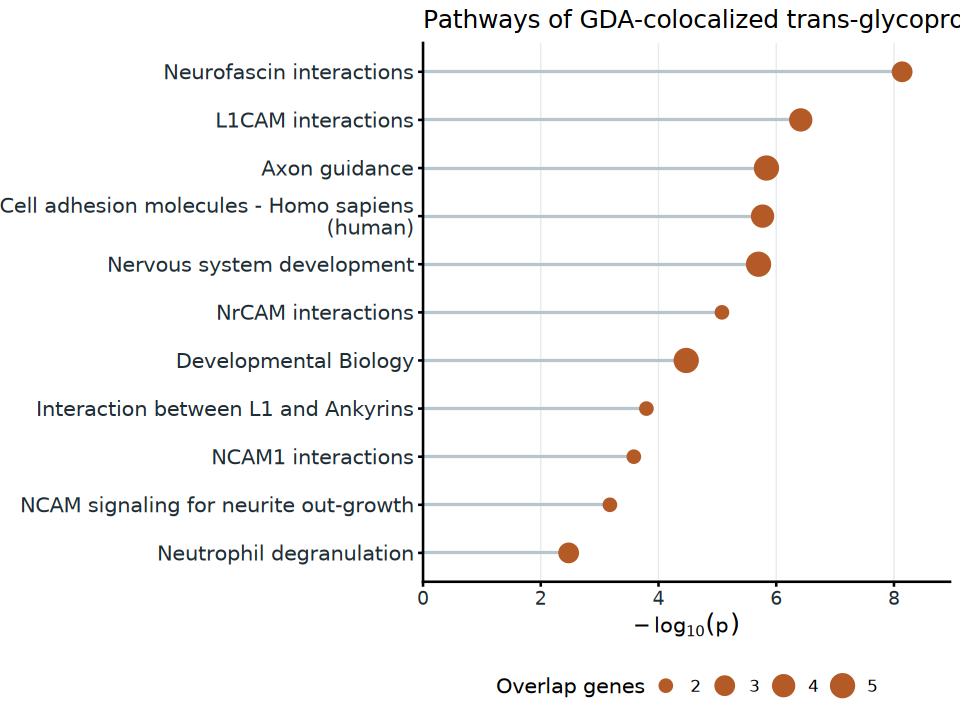

In [2]:
lollipop <- function(d, title, colour = "#28749A", wrap = 45, size_breaks = NULL, xmax = NULL) {
  if (is.null(xmax)) xmax <- max(d$neg_log10_p) * 1.1
  d <- d[order(d$p_value, d$pathway), ]
  d$label <- vapply(d$label, function(x) paste(strwrap(x, width = wrap), collapse = "\n"), character(1))
  d$label <- factor(d$label, levels = rev(d$label))
  ggplot(d, aes(x = neg_log10_p, y = label)) +
    geom_segment(aes(x = 0, xend = neg_log10_p, yend = label), colour = "#B7C5CD", linewidth = 0.7) +
    geom_point(aes(size = overlap_n), colour = colour) +
    scale_size_continuous(name = "Overlap genes", range = c(3, 6),
                          breaks = if (is.null(size_breaks)) sort(unique(d$overlap_n)) else size_breaks,
                          limits = if (is.null(size_breaks)) NULL else range(size_breaks)) +
    scale_x_continuous(limits = c(0, xmax), expand = expansion(mult = c(0, 0))) +
    labs(title = title, x = expression(-log[10](italic(p))), y = NULL) +
    theme_classic(base_size = 12) +
    theme(axis.text.y = element_text(size = 12, colour = "#1F2D35", lineheight = 0.9),
          axis.text.x = element_text(size = 11, colour = "#1F2D35"),
          legend.position = "bottom",
          panel.grid.major.x = element_line(colour = "#E6EBEE", linewidth = 0.3))
}

p <- lollipop(d, "Pathways of GDA-colocalized trans-glycoproteins", colour = "#B35A27")
options(repr.plot.width = 8, repr.plot.height = 6)
p